In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

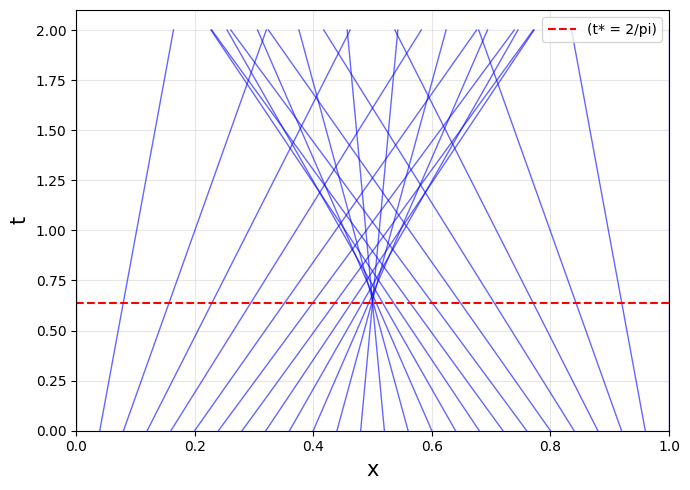

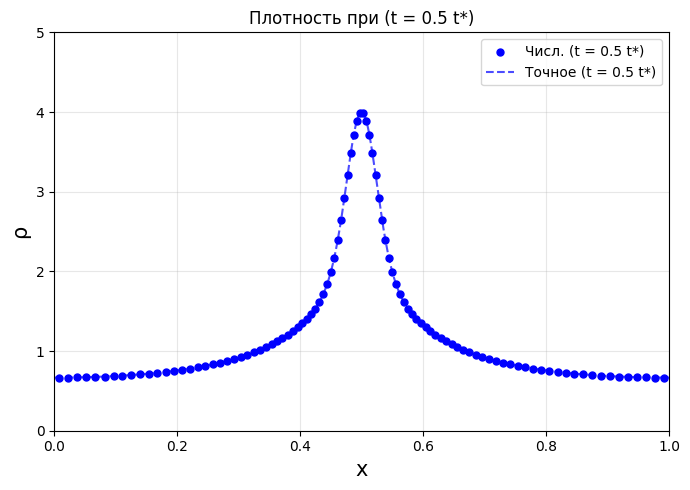

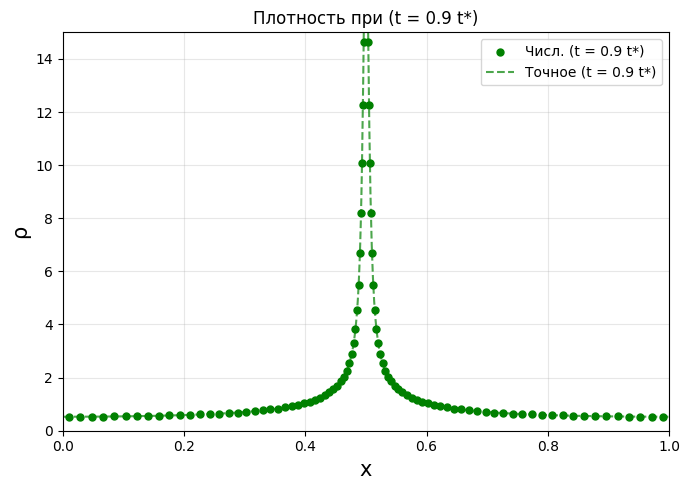

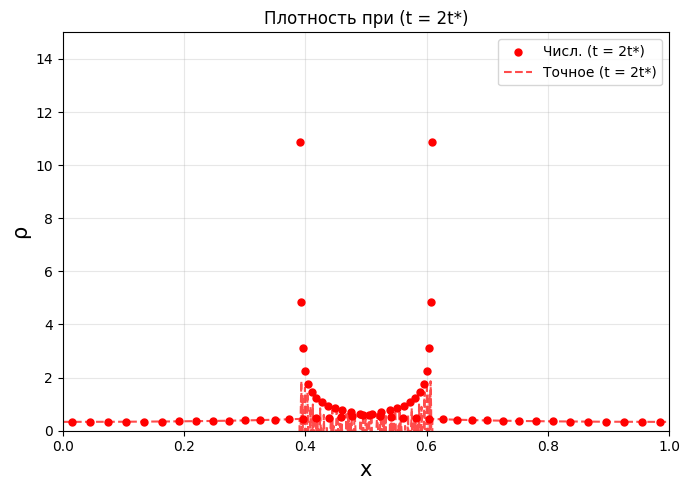

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

N = 100
t_star = 2.0 / np.pi
t_1 = 0.5 * t_star
t_2 = 0.9 * t_star

def u0(x):
    return 0.25 * np.sin(2 * np.pi * x)

def rho0(x):
    return 1.0 + np.exp(-(x - 0.5)**2 / (2 * 0.05**2))

def exact_solution(x, t):
    xi = np.linspace(0, 1, 10000)
    x_traj = xi + u0(xi) * t
    rho_exact = rho0(xi) / (1 + 0.25 * 2 * np.pi * np.cos(2 * np.pi * xi) * t)
    idx = np.argsort(x_traj)
    return np.interp(x, x_traj[idx], rho_exact[idx])

x_nodes_0 = np.linspace(0, 1, N + 1)
u_nodes = u0(x_nodes_0)

masses = np.zeros(N)
for i in range(N):
    mass, _ = quad(rho0, x_nodes_0[i], x_nodes_0[i+1])
    masses[i] = mass

def get_positions_and_density(t):
    x_nodes_t = x_nodes_0 + u_nodes * t
    dx_t = x_nodes_t[1:] - x_nodes_t[:-1]
    rho_t = masses / dx_t
    x_centers = (x_nodes_t[1:] + x_nodes_t[:-1]) / 2.0
    return x_centers, rho_t

x_dense = np.linspace(0, 1, 1000)

fig1, ax1 = plt.subplots(figsize=(7, 5))
t_vals = np.linspace(0, 2, 100)
for i in range(0, N + 1, 4):
    x_traj = x_nodes_0[i] + u_nodes[i] * t_vals
    ax1.plot(x_traj, t_vals, color='blue', alpha=0.6, linewidth=1)

ax1.axhline(t_star, color='red', linestyle='--', label=r'(t* = 2/pi)')
ax1.set_xlabel('x', fontsize=15)
ax1.set_ylabel('t', fontsize=15)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 2.1)
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# t=0.5t*
fig2, ax2 = plt.subplots(figsize=(7, 5))
x_centers_1, rho_1 = get_positions_and_density(t_1)
ax2.scatter(x_centers_1, rho_1, color='blue', s=25, zorder=3, label=f'Числ. (t = 0.5 t*)')
ax2.plot(x_dense, exact_solution(x_dense, t_1), 'b--', alpha=0.7, label='Точное (t = 0.5 t*)')

ax2.set_xlabel('x', fontsize=15)
ax2.set_ylabel('ρ', fontsize=15)
ax2.set_title('Плотность при (t = 0.5 t*)')
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 5)
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# t=0.9t*
fig3, ax3 = plt.subplots(figsize=(7, 5))
x_centers_2, rho_2 = get_positions_and_density(t_2)
ax3.scatter(x_centers_2, rho_2, color='green', s=25, zorder=3, label=f'Числ. (t = 0.9 t*)')
ax3.plot(x_dense, exact_solution(x_dense, t_2), 'g--', alpha=0.7, label='Точное (t = 0.9 t*)')

ax3.set_xlabel('x', fontsize=15)
ax3.set_ylabel('ρ', fontsize=15)
ax3.set_title('Плотность при (t = 0.9 t*)')
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 15)
ax3.legend()
ax3.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# t=t*
fig3, ax3 = plt.subplots(figsize=(7, 5))
x_centers_2, rho_2 = get_positions_and_density(2*t_star)
ax3.scatter(x_centers_2, rho_2, color='red', s=25, zorder=3, label=f'Числ. (t = 2t*)')
ax3.plot(x_dense, exact_solution(x_dense, 2*t_star), 'r--', alpha=0.7, label='Точное (t = 2t*)')

ax3.set_xlabel('x', fontsize=15)
ax3.set_ylabel('ρ', fontsize=15)
ax3.set_title('Плотность при (t = 2t*)')
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 15)
ax3.legend()
ax3.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

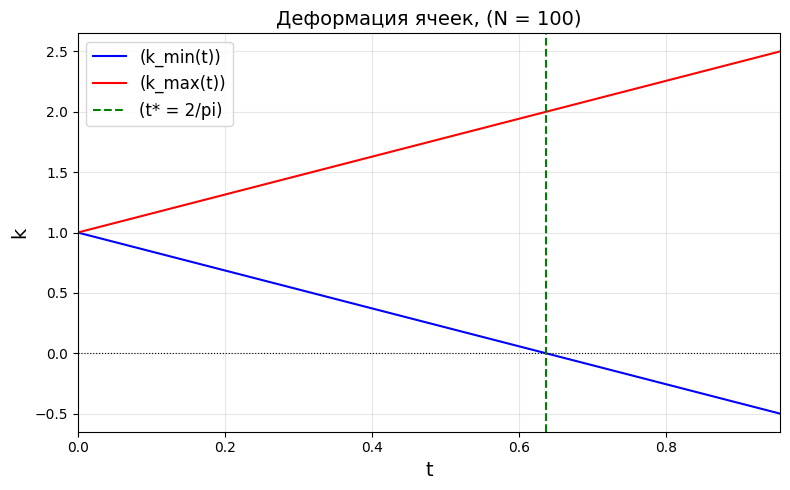

     N |       t_числ |   t* (точно) |   Отличие, %
------------------------------------------------------------
    50 |     0.638298 |     0.636620 |      0.2637%
   100 |     0.637039 |     0.636620 |      0.0658%
   200 |     0.636725 |     0.636620 |      0.0165%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

t_star = 2.0 / np.pi
N_values = [50, 100, 200]

def u0(x):
    return 0.25 * np.sin(2 * np.pi * x)

N = 100
x_nodes_0 = np.linspace(0, 1, N + 1)
u_nodes = u0(x_nodes_0)
dx_0 = x_nodes_0[1:] - x_nodes_0[:-1]
du_cells = u_nodes[1:] - u_nodes[:-1]

t_array = np.linspace(0, 1.5 * t_star, 500)

k_min = np.zeros_like(t_array)
k_max = np.zeros_like(t_array)

for idx, t in enumerate(t_array):
    dx_t = dx_0 + du_cells * t
    k = dx_t / dx_0
    k_min[idx] = np.min(k)
    k_max[idx] = np.max(k)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_array, k_min, 'b-', label=r'(k_min(t))')
ax.plot(t_array, k_max, 'r-', label=r'(k_max(t))')
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.axvline(t_star, color='green', linestyle='--', label=r'(t* = 2/pi)')
ax.set_xlabel('t', fontsize=14)
ax.set_ylabel('k', fontsize=14)
ax.set_title(f'Деформация ячеек, (N = {N})', fontsize=14)
ax.set_xlim(0, 1.5 * t_star)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("=" * 60)
print(f"{'N':>6} | {'t_числ':>12} | {'t* (точно)':>12} | {'Отличие, %':>12}")
print("-" * 60)

for N in N_values:
    x_n = np.linspace(0, 1, N + 1)
    u_n = u0(x_n)
    dx_0_n = x_n[1:] - x_n[:-1]
    du_n = u_n[1:] - u_n[:-1]

    compress = du_n < 0
    if np.any(compress):
        t_turn = -dx_0_n[compress] / du_n[compress]
        t_first = np.min(t_turn)
    else:
        t_first = np.inf

    diff = abs(t_first - t_star) / t_star * 100
    print(f"{N:>6} | {t_first:>12.6f} | {t_star:>12.6f} | {diff:>11.4f}%")

print("=" * 60)

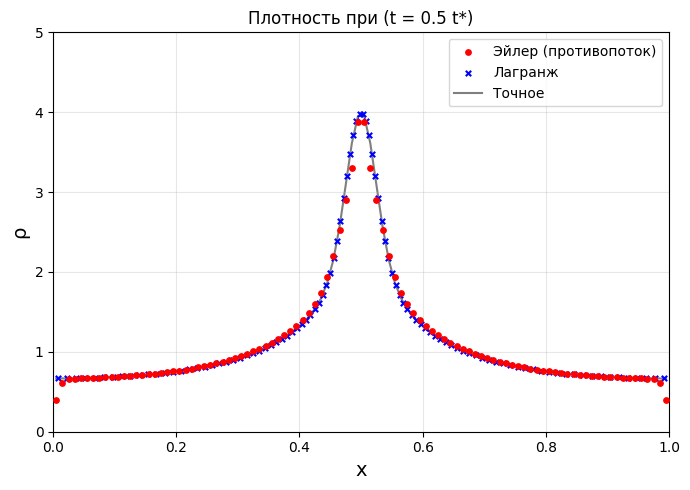

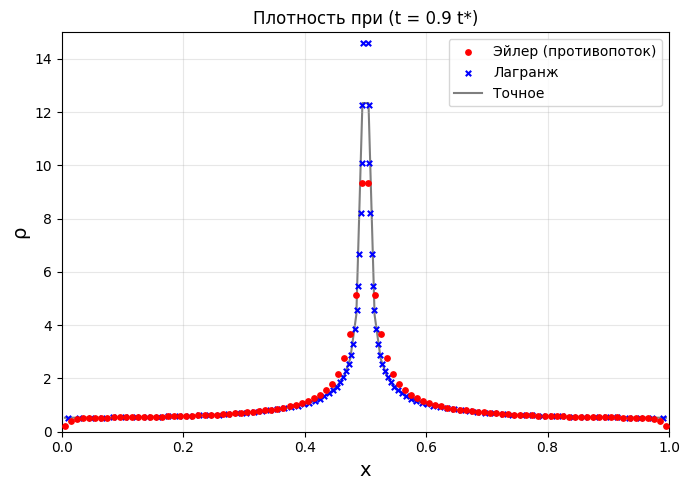

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 100
t_star = 2.0 / np.pi
t_1 = 0.5 * t_star
t_2 = 0.9 * t_star
C = 0.5  # Число Куранта

def u0(x):
    return 0.25 * np.sin(2 * np.pi * x)

def rho0(x):
    return 1.0 + np.exp(-(x - 0.5)**2 / (2 * 0.05**2))

def exact_solution(x, t):
    xi = np.linspace(0, 1, 10000)
    x_traj = xi + u0(xi) * t
    rho_exact = rho0(xi) / (1 + 0.25 * 2 * np.pi * np.cos(2 * np.pi * xi) * t)
    idx = np.argsort(x_traj)
    return np.interp(x, x_traj[idx], rho_exact[idx])


def solve_euler(N):
    h = 1.0 / N
    x_c = np.linspace(h/2, 1 - h/2, N)

    rho = rho0(x_c)
    u = u0(x_c)
    mom = rho * u

    t = 0.0
    rho_1 = None
    rho_2 = None

    target_times = [t_1, t_2]
    current_target_idx = 0

    while t < t_2 - 1e-10:
        max_u = np.max(np.abs(u))
        if max_u < 1e-10:
            tau = t_2 - t
        else:
            tau = C * h / max_u

        if current_target_idx < len(target_times):
            t_target = target_times[current_target_idx]
            if t + tau >= t_target:
                tau = t_target - t

        u_face = np.zeros(N + 1)
        u_face[1:-1] = 0.5 * (u[:-1] + u[1:])
        u_face[0] = u_face[-2]
        u_face[-1] = u_face[1]

        F_rho = np.zeros(N + 1)
        F_mom = np.zeros(N + 1)

        for i in range(1, N):
            if u_face[i] >= 0:
                F_rho[i] = rho[i-1] * u_face[i]
                F_mom[i] = mom[i-1] * u_face[i]
            else:
                F_rho[i] = rho[i] * u_face[i]
                F_mom[i] = mom[i] * u_face[i]

        if u_face[0] >= 0:
            F_rho[0] = rho[-1] * u_face[0]
            F_mom[0] = mom[-1] * u_face[0]
        else:
            F_rho[0] = rho[0] * u_face[0]
            F_mom[0] = mom[0] * u_face[0]

        if u_face[-1] >= 0:
            F_rho[-1] = rho[-1] * u_face[-1]
            F_mom[-1] = mom[-1] * u_face[-1]
        else:
            F_rho[-1] = rho[0] * u_face[-1]
            F_mom[-1] = mom[0] * u_face[-1]

        rho_new = rho - (tau / h) * (F_rho[1:] - F_rho[:-1])
        mom_new = mom - (tau / h) * (F_mom[1:] - F_mom[:-1])

        rho_new = np.maximum(rho_new, 1e-10)

        rho = rho_new
        mom = mom_new
        u = mom / rho

        t += tau

        if current_target_idx < len(target_times):
            if abs(t - target_times[current_target_idx]) < 1e-7:
                if current_target_idx == 0:
                    rho_1 = rho.copy()
                elif current_target_idx == 1:
                    rho_2 = rho.copy()
                current_target_idx += 1

    return x_c, rho_1, rho_2

x_c, rho_euler_1, rho_euler_2 = solve_euler(N)

x_nodes_0 = np.linspace(0, 1, N + 1)
u_nodes = u0(x_nodes_0)
masses = np.zeros(N)
for i in range(N):
    x_left = x_nodes_0[i]
    x_right = x_nodes_0[i+1]
    masses[i] = (rho0(x_left) + rho0(x_right)) / 2 * (x_right - x_left)

def get_lagrange(t):
    x_t = x_nodes_0 + u_nodes * t
    dx_t = x_t[1:] - x_t[:-1]
    rho_t = masses / dx_t
    x_centers = (x_t[1:] + x_t[:-1]) / 2.0
    return x_centers, rho_t

x_lag_1, rho_lag_1 = get_lagrange(t_1)
x_lag_2, rho_lag_2 = get_lagrange(t_2)


fig1, ax1 = plt.subplots(figsize=(7, 5))
ax1.scatter(x_c, rho_euler_1, color='red', s=15, label='Эйлер (противопоток)', zorder=3)
ax1.scatter(x_lag_1, rho_lag_1, color='blue', s=15, marker='x', label='Лагранж', zorder=2)
ax1.plot(x_c, exact_solution(x_c, t_1), 'k-', alpha=0.5, label='Точное', zorder=1)
ax1.set_title('Плотность при (t = 0.5 t*)')
ax1.set_xlabel('x', fontsize=14)
ax1.set_ylabel('ρ', fontsize=14)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 5)
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(7, 5))
ax2.scatter(x_c, rho_euler_2, color='red', s=15, label='Эйлер (противопоток)', zorder=3)
ax2.scatter(x_lag_2, rho_lag_2, color='blue', s=15, marker='x', label='Лагранж', zorder=2)
ax2.plot(x_c, exact_solution(x_c, t_2), 'k-', alpha=0.5, label='Точное', zorder=1)
ax2.set_title('Плотность при (t = 0.9 t*)')
ax2.set_xlabel('x', fontsize=14)
ax2.set_ylabel('ρ', fontsize=14)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 15)
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

    N |  L1_Lagrange | p_Lagrange |     L1_Euler |    p_Euler
-----------------------------------------------------------------
   50 |   4.9244e-03 |          - |   6.1597e-02 |          -
  100 |   1.2680e-03 |       1.96 |   3.3318e-02 |       0.89
  200 |   3.1651e-04 |       2.00 |   2.0596e-02 |       0.69
  400 |   7.9109e-05 |       2.00 |   1.1884e-02 |       0.79
  800 |   1.9675e-05 |       2.01 |   6.3215e-03 |       0.91


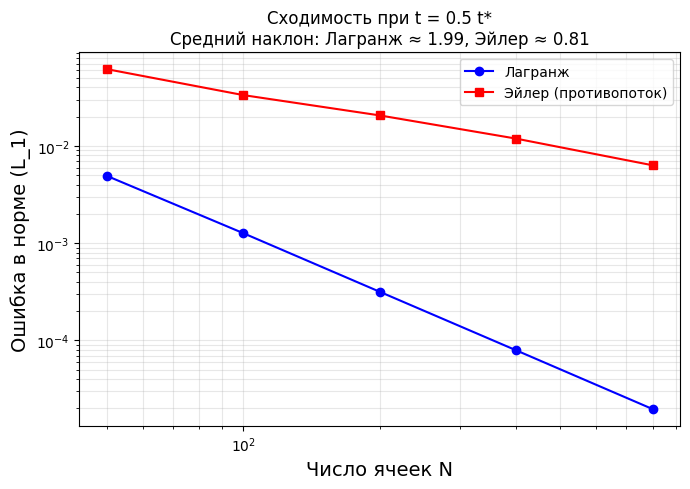

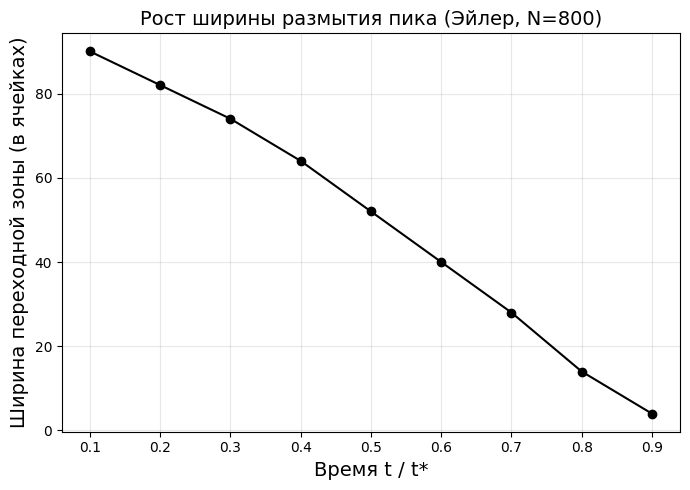

In [7]:
import numpy as np
import matplotlib.pyplot as plt


t_star = 2.0 / np.pi
t_1 = 0.5 * t_star
C = 0.5

def u0(x):
    return 0.25 * np.sin(2 * np.pi * x)

def rho0(x):
    return 1.0 + np.exp(-(x - 0.5)**2 / (2 * 0.05**2))

def exact_solution(x, t):
    xi = np.linspace(0, 1, 10000)
    x_traj = xi + u0(xi) * t
    rho_exact = rho0(xi) / (1 + 0.25 * 2 * np.pi * np.cos(2 * np.pi * xi) * t)
    idx = np.argsort(x_traj)
    return np.interp(x, x_traj[idx], rho_exact[idx])


def solve_lagrange(N, t_target):
    x_nodes_0 = np.linspace(0, 1, N + 1)
    u_nodes = u0(x_nodes_0)
    masses = np.zeros(N)
    for i in range(N):
        x_l, x_r = x_nodes_0[i], x_nodes_0[i+1]
        masses[i] = (rho0(x_l) + rho0(x_r)) / 2 * (x_r - x_l)

    x_t = x_nodes_0 + u_nodes * t_target
    dx_t = x_t[1:] - x_t[:-1]
    rho_t = masses / dx_t
    x_centers = (x_t[1:] + x_t[:-1]) / 2.0
    return x_centers, rho_t

def solve_euler(N, t_target):
    h = 1.0 / N
    x_c = np.linspace(h/2, 1 - h/2, N)

    rho = rho0(x_c)
    u = u0(x_c)
    mom = rho * u

    t = 0.0
    while t < t_target - 1e-10:
        max_u = np.max(np.abs(u))
        tau = C * h / max_u
        if t + tau >= t_target:
            tau = t_target - t

        u_face = np.zeros(N + 1)
        u_face[1:-1] = 0.5 * (u[:-1] + u[1:])
        u_face[0] = u_face[-2]
        u_face[-1] = u_face[1]

        F_rho = np.zeros(N + 1)
        F_mom = np.zeros(N + 1)

        for i in range(1, N):
            if u_face[i] >= 0:
                F_rho[i] = rho[i-1] * u_face[i]
                F_mom[i] = mom[i-1] * u_face[i]
            else:
                F_rho[i] = rho[i] * u_face[i]
                F_mom[i] = mom[i] * u_face[i]

        if u_face[0] >= 0:
            F_rho[0] = rho[-1] * u_face[0]
            F_mom[0] = mom[-1] * u_face[0]
        else:
            F_rho[0] = rho[0] * u_face[0]
            F_mom[0] = mom[0] * u_face[0]

        if u_face[-1] >= 0:
            F_rho[-1] = rho[-1] * u_face[-1]
            F_mom[-1] = mom[-1] * u_face[-1]
        else:
            F_rho[-1] = rho[0] * u_face[-1]
            F_mom[-1] = mom[0] * u_face[-1]

        rho_new = rho - (tau / h) * (F_rho[1:] - F_rho[:-1])
        mom_new = mom - (tau / h) * (F_mom[1:] - F_mom[:-1])

        rho = np.maximum(rho_new, 1e-10)
        mom = mom_new
        u = mom / rho
        t += tau

    return x_c, rho

N_values = [50, 100, 200, 400, 800]
err_lag = []
err_eul = []


for i, N in enumerate(N_values):
    x_lag, rho_lag = solve_lagrange(N, t_1)
    rho_exact_lag = exact_solution(x_lag, t_1)
    err_l = np.sum(np.abs(rho_lag - rho_exact_lag)) / N
    err_lag.append(err_l)
    x_eul, rho_eul = solve_euler(N, t_1)
    rho_exact_eul = exact_solution(x_eul, t_1)
    err_e = np.sum(np.abs(rho_eul - rho_exact_eul)) / N
    err_eul.append(err_e)
    if i > 0:
        p_l = np.log2(err_lag[i-1] / err_lag[i])
        p_e = np.log2(err_eul[i-1] / err_eul[i])
        print(f"{N:>5} | {err_l:>12.4e} | {p_l:>10.2f} | {err_e:>12.4e} | {p_e:>10.2f}")
    else:
        print(f"{N:>5} | {err_l:>12.4e} | {'-':>10} | {err_e:>12.4e} | {'-':>10}")

fig1, ax1 = plt.subplots(figsize=(7, 5))
ax1.loglog(N_values, err_lag, 'bo-', label='Лагранж')
ax1.loglog(N_values, err_eul, 'rs-', label='Эйлер (противопоток)')
p_lag_avg = -np.polyfit(np.log(N_values), np.log(err_lag), 1)[0]
p_eul_avg = -np.polyfit(np.log(N_values), np.log(err_eul), 1)[0]

ax1.set_xlabel('Число ячеек N', fontsize=14)
ax1.set_ylabel(r'Ошибка в норме (L_1)', fontsize=14)
ax1.set_title(f'Сходимость при t = 0.5 t*\nСредний наклон: Лагранж ≈ {p_lag_avg:.2f}, Эйлер ≈ {p_eul_avg:.2f}', fontsize=12)
ax1.grid(True, which="both", alpha=0.3)
ax1.legend()
plt.tight_layout()
plt.show()


N_fixed = 800

h_fixed = 1.0 / N_fixed
times = np.linspace(0.1 * t_star, 0.9 * t_star, 9)
widths_cells = []

for t in times:
    x_eul, rho_eul = solve_euler(N_fixed, t)

    rho_max = np.max(rho_eul)
    background = 1.0
    threshold = background + (rho_max - background) / 2.0

    mask = rho_eul > threshold
    if np.any(mask):
        width_in_cells = np.sum(mask)
        widths_cells.append(width_in_cells)
    else:
        widths_cells.append(0)

fig2, ax2 = plt.subplots(figsize=(7, 5))
ax2.plot(times / t_star, widths_cells, 'ko-', markersize=6)
ax2.set_xlabel(r'Время t / t*', fontsize=14)
ax2.set_ylabel(r'Ширина переходной зоны (в ячейках)', fontsize=14)
ax2.set_title(f'Рост ширины размытия пика (Эйлер, N={N_fixed})', fontsize=14)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()